# Credit Card Spending Prediction – PAC Report
### Best Approaches & Experiments

**Analyst:** Darren Lin 
**Date:** November 24, 2025

## 1. Project Overview
This report details my data analysis process and key learnings from the Predictive Analytics Competition (PAC).
The primary objective was to predict each customer's monthly credit card spending using a tabular dataset, evaluated by minimizing Root Mean Squared Error (RMSE).
This approach focused on thorough data exploration, aggressive feature engineering, robust pipeline design, and validation with advanced ensemble models.

## 2. Data Exploration and Insights
Initial data exploration involved loading and profiling the datasets to understand their structure and missingness.
I checked basic statistics, value ranges, data types, and missing values.

In [2]:
import pandas as pd

# Load datasets
train_df = pd.read_csv('analysis_data.csv')
scoring_df = pd.read_csv('scoring_data.csv')

print("Training data shape:", train_df.shape)
print("Scoring data shape:", scoring_df.shape)

# Explore dtypes and missing values
display(train_df.info())
display(train_df.describe())

Training data shape: (40000, 23)
Scoring data shape: (10000, 22)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 23 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   customer_id            40000 non-null  int64  
 1   age                    40000 non-null  int64  
 2   gender                 40000 non-null  object 
 3   marital_status         40000 non-null  object 
 4   education_level        38801 non-null  object 
 5   region                 40000 non-null  object 
 6   employment_status      40000 non-null  object 
 7   owns_home              40000 non-null  int64  
 8   has_auto_loan          40000 non-null  int64  
 9   annual_income          40000 non-null  float64
 10  credit_score           40000 non-null  float64
 11  credit_limit           40000 non-null  float64
 12  tenure                 40000 non-null  int64  
 13  card_type              40000 non-null  ob

None

,customer_id,age,owns_home,has_auto_loan,annual_income,credit_score,credit_limit,tenure,num_transactions,avg_transaction_value,online_shopping_freq,reward_points_balance,travel_frequency,utility_payment_count,num_children,num_credit_cards,monthly_spend
count,4.000000e+04,40000.000000,40000.000000,40000.000000,40000.000000,40000.000000,40000.000000,40000.000000,40000.000000,40000.000000,37992.000000,40000.000000,40000.000000,39202.000000,40000.000000,40000.00000,40000.000000
mean,5.516258e+07,49.063900,0.502825,0.502925,62466.009961,699.878580,14573.193459,9.514575,11.275000,37.433152,8.111866,7250.912784,2.870675,3.250446,1.109100,7.98765,1666.201508
std,2.595662e+07,18.175343,0.499998,0.499998,49656.884438,50.247404,11791.285872,5.780889,6.038422,20.037322,3.809252,4975.085861,2.258988,2.061360,1.152771,0.19621,537.303898
min,1.000088e+07,18.000000,0.000000,0.000000,2277.888686,470.895415,461.048761,0.000000,0.000000,4.417843,0.000000,571.531405,0.000000,0.000000,0.000000,1.00000,99.080000
25%,3.261957e+07,33.000000,0.000000,0.000000,30478.024000,665.682600,7007.302229,5.000000,7.000000,23.612979,5.000000,4053.616363,1.000000,2.000000,0.000000,8.00000,1309.502500
50%,5.541669e+07,49.000000,1.000000,1.000000,48800.257192,700.208341,11281.194224,10.000000,10.000000,32.983460,8.000000,5894.362787,2.000000,3.000000,1.000000,8.00000,1609.915000
75%,7.758322e+07,65.000000,1.000000,1.000000,78217.444607,733.811768,18282.105567,15.000000,14.000000,46.329229,10.000000,8827.159632,4.000000,4.000000,2.000000,8.00000,1953.395000
max,9.999871e+07,80.000000,1.000000,1.000000,720441.690363,850.000000,191517.788605,19.000000,80.000000,240.927091,45.000000,73100.957963,29.000000,20.000000,6.000000,8.00000,8924.360000


Visual Exploration

Understanding the target's distribution is essential for effective modeling.
Here I plot the distribution of monthly_spend. 

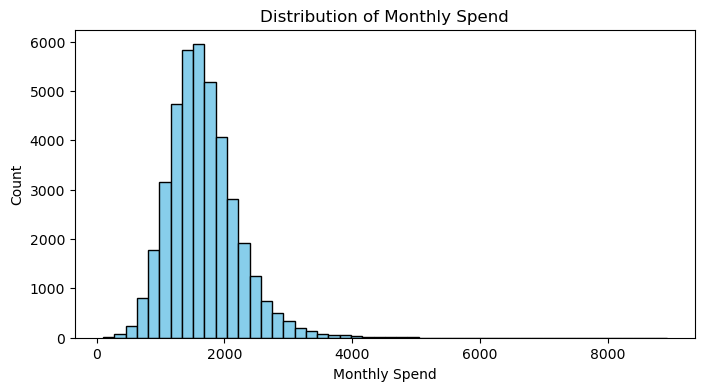

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.hist(train_df['monthly_spend'], bins=50, color='skyblue', edgecolor='black')
plt.title("Distribution of Monthly Spend")
plt.xlabel("Monthly Spend")
plt.ylabel("Count")
plt.show()

## 3. Feature Engineering: Creating High-value Features
Feature engineering had the greatest impact.
I tried engineering new features representing domain insights and meaningful interactions, improving the model’s ability to generalize.

Key features created:

- estimated_spend = transactions × avg_transaction_value

- limit_to_income_ratio, score_x_limit, age_x_income

- online_tx_ratio, tx_per_card

- credit_score_sq (polynomial feature)

In [3]:
def create_features(df):
    """
    Generate features to boost prediction accuracy.
    """
    df_new = df.copy()
    # Estimated spend: Multiplying transaction count by average value
    df_new['estimated_spend'] = df_new['num_transactions'] * df_new['avg_transaction_value']
    # Ratios and interactions
    df_new['limit_to_income_ratio'] = df_new['credit_limit'] / (df_new['annual_income'] + 1e-6)
    df_new['score_x_limit'] = df_new['credit_score'] * df_new['credit_limit']
    df_new['age_x_income'] = df_new['age'] * df_new['annual_income']
    df_new['online_tx_ratio'] = df_new['online_shopping_freq'] / (df_new['num_transactions'] + 1e-6)
    df_new['tx_per_card'] = df_new['num_transactions'] / (df_new['num_credit_cards'] + 1e-6)
    df_new['credit_score_sq'] = df_new['credit_score'] ** 2
    return df_new

# Apply engineered features to both train and scoring data
train_df_fe = create_features(train_df)
scoring_df_fe = create_features(scoring_df)


Visualize an Engineered Feature

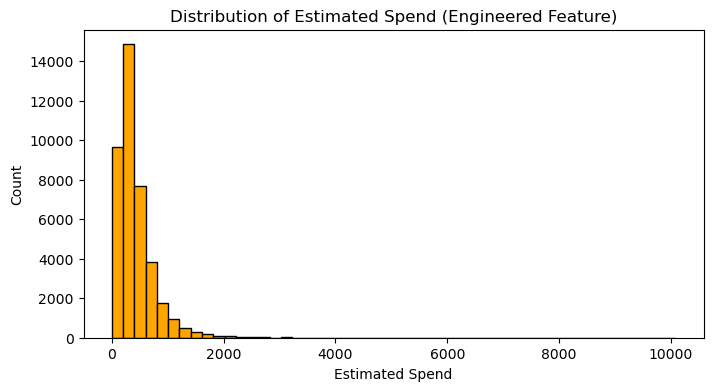

In [11]:
plt.figure(figsize=(8, 4))
plt.hist(train_df_fe['estimated_spend'], bins=50, color='orange', edgecolor='black')
plt.title("Distribution of Estimated Spend (Engineered Feature)")
plt.xlabel("Estimated Spend")
plt.ylabel("Count")
plt.show()

## 4. Data Preparation & Pipeline Construction
Automated data preparation maximizes reproducibility.
Pipeline design included median imputation, categorical encoding, and numeric scaling—fully automated with "ColumnTransformer" and "Pipeline".

In [4]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Set up target and features
target = 'monthly_spend'
features = [c for c in train_df_fe.columns if c not in ['customer_id', target]]

# Identify dtypes
numeric_cols = train_df_fe[features].select_dtypes(include='number').columns.tolist()
categorical_cols = [c for c in features if c not in numeric_cols]

# Numeric: median imputation + scaling
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical: mode imputation + one-hot encoding
categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))
])

# Combine pipelines
preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_cols),
    ('cat', categorical_transformer, categorical_cols)
], remainder='passthrough')

## 5. Model Selection — Stacking Ensemble
The final model I used was a stacking ensemble with Random Forest, Gradient Boosting, and Ridge as base regressors, and a LassoCV meta-model for regularized blending. This gave strong generalization and flexibility.

In [5]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, StackingRegressor
from sklearn.linear_model import Ridge, LassoCV

rf = RandomForestRegressor(n_estimators=150, max_depth=7, random_state=42, n_jobs=-1)
gb = GradientBoostingRegressor(n_estimators=220, learning_rate=0.07, max_depth=6, subsample=0.8, random_state=42)
ridge = Ridge(alpha=1.0, random_state=42)

estimators = [
    ('rf', rf),
    ('gb', gb),
    ('ridge', ridge)
]

stacker = StackingRegressor(
    estimators=estimators, 
    final_estimator=LassoCV(alphas=[0.01, 0.1, 1, 10], cv=5, random_state=42), 
    cv=5,
    n_jobs=-1
)

## 6. Full Model Pipeline with Preprocessing and Modeling
Combine preprocessing and the ensemble for full reproducibility.

In [6]:
model_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('stacker', stacker)
])

## 7. Validation: 5-Fold Cross-Validation
A rigorous validation loop using KFold CV provided reliable RMSE estimates and ensured the model generalized to new data.

In [7]:
from sklearn.model_selection import KFold, cross_val_score
import numpy as np

X = train_df_fe[features]
y = train_df[target]

kf = KFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(model_pipeline, X, y, cv=kf, scoring='neg_root_mean_squared_error', n_jobs=-1)

rmse_scores = -scores
print("--- Robust CV Results ---")
print(f"Mean RMSE: {rmse_scores.mean():.4f}")
print(f"Std Dev RMSE: {rmse_scores.std():.4f}")
print(f"All Scores: {rmse_scores}")

--- Robust CV Results ---
Mean RMSE: 250.1127
Std Dev RMSE: 2.0456
All Scores: [249.13682111 251.89948952 251.65840472 251.3439367  246.52498413]


## 8. Final Model Training and Submission
Train on all data, predict for the scoring dataset, and save the required submission.

In [8]:
# Fit final model
model_pipeline.fit(X, y)

# Prepare scoring set
X_score = scoring_df_fe[features]
score_pred = model_pipeline.predict(X_score)
submission = pd.DataFrame({
    'customer_id': scoring_df['customer_id'],
    'monthly_spend': score_pred
})
submission_filename = 'submission_15.csv'
submission.to_csv(submission_filename, index=False)
print(f"Successfully saved: {submission_filename}")

Successfully saved: submission_15.csv


## 9. Insights & Lessons Learned
**Key lessons:**
- Feature engineering > Model complexity.
- Automated pipelines protected against error and supported rapid experimentation.
- Stacking ensembles were more robust than a single model.
- KFold cross-validation caught overfitting and gave trustworthy RMSE.

**Improvements for next time:**
- Prioritize feature engineering early (First Step).
- Use systematic model selection (e.g., GridSearchCV).
- Track and document each experiment for reproducibility.

Thank You.